<a href="https://colab.research.google.com/github/aiyman14/DACSS-758-Text-as-Data/blob/main/758_final_AA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Beyond VADER: Benchmarking Transformer-Based Sentiment Classifiers (FinBERT, CryptoBERT) on Cryptocurrency News
## DACSS 758: Text as Data
## Aiyman Akbar

## Check In #1 Summary

The corpus that I am using for this project consists of news articles related to Bitcoin and cryptocurrency. I got this dataset from Hugging Face and it contains approximately 2,500 news articles. The articles are collected from various online news sources, including financial news websites, cryptocurrency publications, and general news outlets. Each entry in the dataset is a collection of different things from the article itself, such as the article title, summary text and author. These articles appear to have been aggregated from online news reporting about Bitcoin and cryptocurrency markets.

This dataset was probably created to support research in NLP, financial texts and analyzing them and related fields of research. Because it is an aggregation of crypto related articles it is easy to understand the relationship between digital assets and the media and how news narratives may influence market perception. However, the dataset may contain several sources of bias. Because news coverage tends to focus on major events such as market crashes or technological breakthroughs, this may lead to an overrepresentation of dramatic or high-impact stories. Additionally, different news outlets frame cryptocurrency differently depending on their audience or editorial stance.

I expect the language in the corpus to be pretty formal, in a journalistic style about financial and tech news. These types of articles generally do include jargon and specific terminology related to cryptocurrency, the markets, prices etc. I find this corpus interesting because of the relationship that it allows you to see between cryptocurrency and the media, and specifically how news narratives can influence the price of crypto and vice versa how the price fluctuations of crypto change the public sentiment or news headlines related to cryptocurrency. The corpus is structured as a standard dataset with each row being a single news article with many fields as the columns, and the total word count is around 230,813 words.

## Check In #2 Summary

For Check In #2 I completed preprocessing on the dataset using a series of steps that cleaned up the text and got it ready for analysis. The steps I chose were lowercasing (so that words like "Bitcoin" and "bitcoin" would be treated as the same token), removing punctuation (since it does not really add meaning for this kind of analysis), removing extra whitespace (to clean up the spacing after punctuation was stripped out), removing stopwords (like "the", "is", "and" which are common but do not carry meaning), and removing short words under 3 characters (to get rid of leftover fragments).

I chose these steps because they make sense for the word frequency and sentiment style of analysis that I am doing. I deliberately did not do stemming or lemmatization because I wanted the words to stay readable in visualizations like the word cloud, and I also kept numbers in since things like prices and years can be meaningful in the context I am looking at. The unit of analysis I chose was a single article summary since that field had the most substantial text in the dataset.

## Check In #3 Summary

For Check In #3 I ran two analyses on the preprocessed corpus. The first was dictionary-based sentiment analysis using VADER, which scored each article summary on a positive negative or neutral scale. The second was unsupervised topic modeling using LDA with 5 topics, which surfaced themes around trading and market activity, mining and mining companies, blockchain and investment infrastructure, price movements, and general crypto news.

The main takeaways were that overall sentiment skewed positive, that VADER struggled with crypto-specific vocab like "crash" and "dump", and that the LDA topics were partially fuzzy because dominant words like "bitcoin", "btc", and "crypto" appeared across multiple topics.

At the end of Check In #3 I had two next steps in mind that I am going to do in this project. The first is combining the two methods by computing average sentiment within each LDA topic, and also trying a transformer-based sentiment model that handles crypto-specific language better than VADER.

## Motivation and Research Question

My motivation for this project is that I am interested in the relationship between Bitcoin and the news media, what themes show up in coverage, and how the tone of that coverage compares across different ways of analyzing sentiment. Crypto is also a good test case for whether general NLP tools work outside of settings where they have been trained, because everyday financial words like "crash" and "dump" do not mean the same thing in crypto news as they do in normal English.

For this final notebook the research question I am trying to answer is how does sentiment in Bitcoin news coverage vary across different themes, and how much does the choice of sentiment method (general vs. specific) actually change the picture I see?

Note on runtime: I came across a inconvenience where on a CPU runtime the FinBERT and CryptoBERT take several minutes per model. I would recommend switching to t4 GPU runtime in Colab before running this notebook.

## Setup and Loading Data

In [ ]:
# install required libraries
!pip install -q datasets gensim wordcloud pyLDAvis transformers torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 48.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 60.9 MB/s eta 0:00:00


In [ ]:
# imports
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from wordcloud import WordCloud

# for preprocessing
from gensim.parsing.preprocessing import preprocess_string, strip_tags, strip_punctuation, strip_short
from gensim.parsing.preprocessing import strip_multiple_whitespaces, strip_numeric, remove_stopwords

# for sentiment analysis (VADER)
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# for topic modeling
from gensim.corpora import Dictionary
from gensim.models import LdaModel
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

# for transformer-based sentiment (FinBERT, CryptoBERT)
from transformers import pipeline
import torch

import warnings
warnings.filterwarnings('ignore')

<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyPacked has no __module__ attribute
<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyObject has no __module__ attribute
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and sche

In [ ]:
# load dataset directly from Hugging Face
ds = load_dataset("khaihernlow/bitcoin-news-articles-text-corpora")
df = pd.DataFrame(ds["train"])

# drop rows with missing summaries
df = df.dropna(subset=['summary']).reset_index(drop=True)
print("Shape:", df.shape)
df.head()

data/bitcoin_articles.jsonl:   0%|          | 0.00/3.50M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/2500 [00:00<?, ? examples/s]

Shape: (2500, 17)


,article_id,title,author,published_date,link,clean_url,excerpt,summary,rights,article_rank,topic,country,language,authors,media,twitter_account,article_score
0,57a00c1140cbd3af79e77bf0e4e6af48,62% of Bitcoin Has Not Moved in a Year as Long...,Jamie McNeill,04-10-2022 17:15,https://www.business2community.com/crypto-news...,business2community.com,"Over the course of the last few years, there h...","Over the course of the last few years, there h...",business2community.com,1595,finance,US,en,Jamie McNeill,https://www.business2community.com/wp-content/...,@Jamie_DeFi,8.556426
1,21b48b3731c03466be3fac4be6c7dc67,The Orange Party Issue Playlist,Bitcoin Magazine,05-10-2022 21:17,https://bitcoinmagazine.com/culture/orange-par...,bitcoinmagazine.com,News Links: Russia Legalizing Bitcoin And Cryp...,Russia Legalizing Bitcoin And Crypto Is A Matt...,bitcoinmagazine.com,6284,news,US,en,Bitcoin Magazine,https://bitcoinmagazine.com/.image/t_share/MTk...,N/A,8.507881
2,77030740ee160ad68c25e4e63515dd77,How Many Bitcoins Are There?,AOL Staff,04-10-2022 21:44,https://www.gobankingrates.com/investing/crypt...,gobankingrates.com,Bitcoin has a maximum supply of 21 million. Ho...,Bitcoin has a maximum supply of 21 million. Ho...,aol.com,5044,news,US,en,"AOL Staff,David Granahan",https://s.yimg.com/ny/api/res/1.2/wPK4V8gjwjrD...,@AOL,8.483973
3,19285dde79599b6a9b4aa5a58805159b,Bitcoin 2008â2022: From Bouncing Baby To Tro...,Mark Hooson,03-10-2022 15:45,https://www.forbes.com/advisor/au/investing/bi...,forbes.com,"Conceived in 2008 and launched in 2009, bitcoi...","Conceived inÂ 2008Â and launched inÂ 2009, bit...",forbes.com,49,business,US,en,"Forbes Staff,Kevin Pratt,Mark Hooson,Sophie Venz",https://thumbor.forbes.com/thumbor/fit-in/x/ht...,N/A,8.466393
4,ad1822c7ff1bbd7e38f7f9dbdbce245f,"Bitcoin Lightning Network capacity strikes 5,0...",Joseph Hall,03-10-2022 12:09,https://cointelegraph.com/news/bitcoin-lightni...,cointelegraph.com,"First created in 2018, the Lighting Network ha...",Bear markets are for building out capacity on ...,cointelegraph.com,1696,news,US,en,Joseph Hall,https://images.cointelegraph.com/images/1200_a...,@cointelegraph,8.446906


In [ ]:
# topic distribution
print("Topic distribution:")
print(df['topic'].value_counts())

Topic distribution:
topic
news             1985
finance           388
business           79
tech               20
economics          11
world               6
entertainment       3
beauty              2
science             2
sport               1
politics            1
food                1
energy              1
Name: count, dtype: int64


In [ ]:
# parse the publication dates
df['date'] = pd.to_datetime(df['published_date'], format='%d-%m-%Y %H:%M', errors='coerce')
print("Date range:", df['date'].min(), "to", df['date'].max())
print("Articles with valid dates:", df['date'].notna().sum(), "/", len(df))

Date range: 2022-10-03 00:00:00 to 2022-10-09 23:56:00
Articles with valid dates: 2500 / 2500


The articles all fall within a 7-day window from October 3 to October 9, 2022, which is something I did not realize was the case when I picked the dataset. That is a much narrower time range than I assumed. The "topic" column is also pretty unbalanced. Most articles are tagged as "news" (1985 articles), with much smaller groups in "finance" (388), "business" (79), "tech" (20), and "economics" (11). I keep both of these facts in mind when I do any topic comparisons later in the analysis.

## Preprocessing

For this dataset, I am using the article "summary" field as my main text for analysis since it contains the most substantial text content for each article. The unit of analysis is a single article, represented by its summary. Below I will walk through each preprocessing step I chose to complete and explain why.

First, here is an example of what one article summary looks like before any preprocessing:

In [ ]:
# before preprocessing
summaries = df['summary'].tolist()
example_idx = 0

print(summaries[example_idx])

BEFORE PREPROCESSING
Over the course of the last few years, there has been an impressive trend when it comes Bitcoin hodlers. The number of long-term holders is always rising, and it has now reached the point that 62% of all Bitcoin has not been moved in at least a year.

62% of Bitcoin has not moved in a year

The significance of not moving so much Bitcoin is that the asset becomes far scarcer.

As more and more Bitcoin stays still, there are fewer Bitcoin being sent to exchanges to be traded and fewer Bitcoin that can be sold on the market.


### Step 1: Lowercasing

I am converting all text to lowercase so that words like "Bitcoin" and "bitcoin" are treated as the same token. Without this step the same word would be counted separately just because of capitalization which would mess up frequency counts and general analysis.

In [ ]:
# Step 1: lowercase
summaries_lower = [item.lower() for item in summaries]

### Step 2: Remove Punctuation

Punctuation does not really add any meaning for the kind of text analysis that I want to do with this dataset. Things like commas, periods, quotation marks etc would just add noise to the data and mess up tokenization, so I am remoivng all of them.

### Step 3: Remove Extra Whitespace

After removing punctuation and other characters there will probably be extra spaces left over in certain places. Stripping multiple whitespaces should clean things up and makes sure tokens are separated properly.

### Step 4: Remove Stopwords

Stopwords are common words like "the", "is", "and", "of" etc. that appear very frequently but will not carry much meaning for my analysis. If I kept them in they would dominate the word frequencies and make it harder to see the actual important terms related to Bitcoin and cryptocurrency news. Removing them will let the more meaningful content words stand out.

### Step 5: Remove Short Words

I am also removing words that are shorter than 3 characters. These could be leftover fragments or very common words that wont really add value to my analysis, like the stopwords from step 4. This will be like a second layer after removing the stopwords.

In [ ]:
# Steps 2-5
CUSTOM_FILTERS = [strip_punctuation, strip_multiple_whitespaces, remove_stopwords, strip_short]
summaries_toks = [preprocess_string(item, CUSTOM_FILTERS) for item in summaries_lower]
print(summaries_toks[0])

['course', 'years', 'impressive', 'trend', 'comes', 'bitcoin', 'hodlers', 'number', 'long', 'term', 'holders', 'rising', 'reached', 'point', 'bitcoin', 'moved', 'year', 'bitcoin', 'moved', 'year', 'significance', 'moving', 'bitcoin', 'asset', 'far', 'scarcer', 'bitcoin', 'stays', 'fewer', 'bitcoin', 'sent', 'exchanges', 'traded', 'fewer', 'bitcoin', 'sold', 'market']


### Deliberately Omitted Steps

I chose not to remove numbers because in financial news articles numbers like prices and percentages can be meaningful, but I may reconsider this depending on what I finaly decide to look for in my analysis later in the process.

In [ ]:
# merge tokens back after steps 2-5 into strings for the upcoming steps
summaries_toks_merged = [' '.join(item) for item in summaries_toks]

### After Preprocessing Example

Now here is the same article after all the preprocessing steps have been applied:

In [ ]:
# same article AFTER preprocessing

print(summaries_toks_merged[example_idx])

AFTER PREPROCESSING
course years impressive trend comes bitcoin hodlers number long term holders rising reached point bitcoin moved year bitcoin moved year significance moving bitcoin asset far scarcer bitcoin stays fewer bitcoin sent exchanges traded fewer bitcoin sold market


## Visualizations

### Visualization 1: Top 25 Most Frequent Words

This bar chart shows the 25 most common words across all the article summaries after preprocessing. This is helpful because it gives a clear picture of what the dominant themes and topics are in Bitcoin news coverage. If certain words show up way more than others, that says something about what the media focuses on when they talk about Bitcoin and cryptocurrency.

In [ ]:
# all tokens into one list
all_tokens = [item for sublist in summaries_toks for item in sublist]
print("Total tokens:", len(all_tokens))

# count frequencies
c = Counter(all_tokens)
word_df = pd.DataFrame(c.items(), columns=['Token', 'Count'])
word_df = word_df.sort_values(by='Count', ascending=False)
word_df.head(10)

Total tokens: 120867


,Token,Count
5,bitcoin,5681
180,btc,1359
27,market,1208
30,crypto,1185
25,traded,955
129,cryptocurrency,856
62,mining,818
200,2022,813
563,digital,758
161,price,690


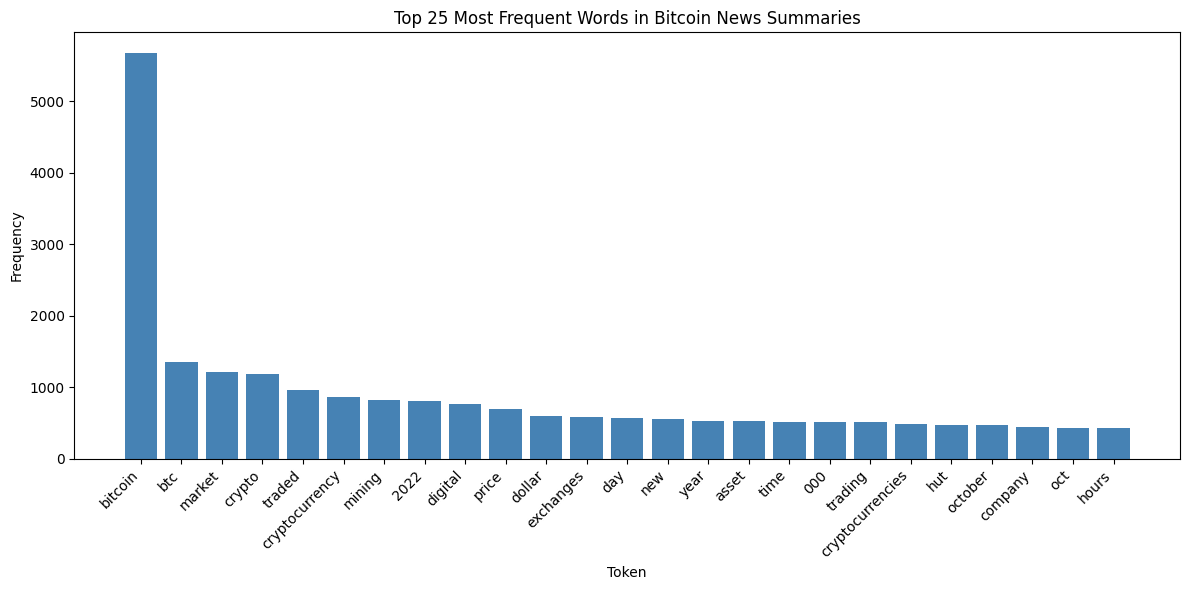

In [ ]:
# plot top 25 most frequent words
top25 = word_df.head(25)

plt.figure(figsize=(12, 6))
plt.bar(top25['Token'], top25['Count'], color='steelblue')
plt.xticks(rotation=45, ha='right')
plt.xlabel('Token')
plt.ylabel('Frequency')
plt.title('Top 25 Most Frequent Words in Bitcoin News Summaries')
plt.tight_layout()
plt.show()

### Visualization 2: Word Cloud

I like the world cloud as a way to visualize the same frequency data but in a more visually interesting way. This format makes it easy to see at a glance what the most prominent terms are in the dataset. It is also just a nice visual to include in my opinion because it immediately communicates what the corpus is about.

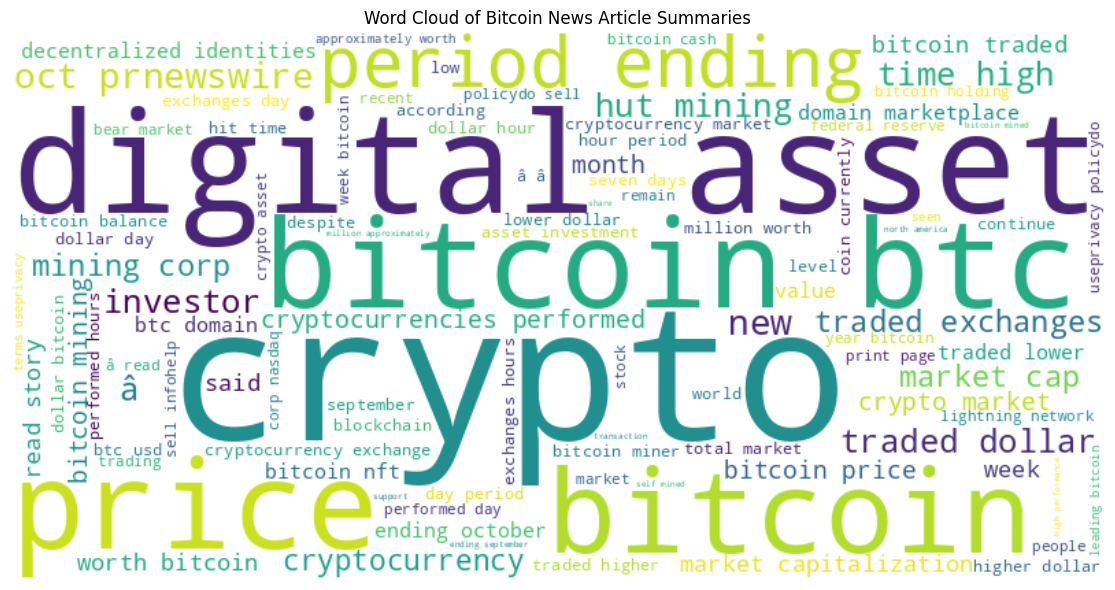

In [ ]:
# create word cloud from all preprocessed text
all_text = ' '.join(summaries_toks_merged)

wordcloud = WordCloud(width=800, height=400,
                      background_color='white',
                      colormap='viridis',
                      max_words=100).generate(all_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Bitcoin News Article Summaries')
plt.tight_layout()
plt.show()

# Analysis


## Method 1: Dictionary-Based Sentiment Analysis (VADER)

For my first method I chose dictionary-based sentiment analysis using VADER. I used VADER to look up each word in a pre-built sentiment dictionary and gives four scores: positive, negative, neutral, and a compound score from -1 to +1. I chose this method because one of my main interests from Check In #1 was how news narratives might influence market perception, and sentiment is a natural way to measure that. I ran VADER on the preprocessed summaries and also broke the results down by the "topic" column to see if sentiment differs across article categories.

In [ ]:
# download VADER lexicon
nltk.download('vader_lexicon')

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


True

In [ ]:
# instantiate analyzer
analyzer = SentimentIntensityAnalyzer()

# calculate sentiment scores for each article summary
scores = [analyzer.polarity_scores(s) for s in summaries_toks_merged]
df['compound'] = [s['compound'] for s in scores]
df['positive'] = [s['pos'] for s in scores]
df['negative'] = [s['neg'] for s in scores]
df['neutral'] = [s['neu'] for s in scores]

df[['title', 'topic', 'compound', 'positive', 'negative', 'neutral']].head()

,title,topic,compound,positive,negative,neutral
0,62% of Bitcoin Has Not Moved in a Year as Long...,finance,0.8225,0.249,0.000,0.751
1,The Orange Party Issue Playlist,news,0.4404,0.118,0.028,0.854
2,How Many Bitcoins Are There?,news,0.1531,0.084,0.074,0.842
3,Bitcoin 2008â2022: From Bouncing Baby To Tro...,business,0.6486,0.114,0.000,0.886
4,"Bitcoin Lightning Network capacity strikes 5,0...",news,0.8503,0.207,0.000,0.793


In [ ]:
# overall sentiment stats
print("Overall sentiment statistics:")
print(df[['compound', 'positive', 'negative', 'neutral']].describe())

Overall sentiment statistics:
          compound     positive     negative      neutral
count  2500.000000  2500.000000  2500.000000  2500.000000
mean      0.357699     0.130683     0.051436     0.807093
std       0.513653     0.089671     0.066630     0.133978
min      -0.989100     0.000000     0.000000     0.000000
25%       0.000000     0.065750     0.000000     0.739750
50%       0.510600     0.116000     0.030000     0.825000
75%       0.802000     0.186000     0.086000     0.895000
max       0.987000     0.524000     0.394000     1.000000


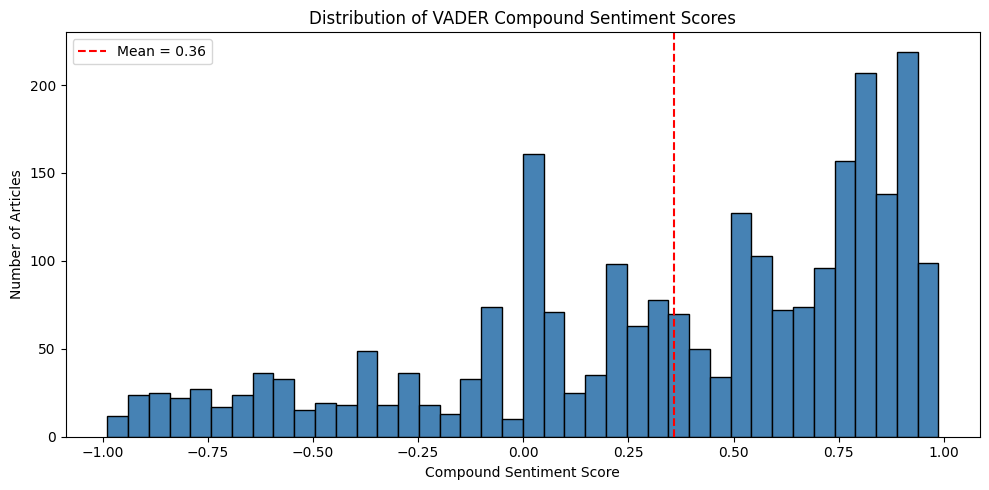

In [ ]:
# plot distribution of compound scores
plt.figure(figsize=(10, 5))
plt.hist(df['compound'], bins=40, color='steelblue', edgecolor='black')
plt.axvline(df['compound'].mean(), color='red', linestyle='--', label=f"Mean = {df['compound'].mean():.2f}")
plt.xlabel('Compound Sentiment Score')
plt.ylabel('Number of Articles')
plt.title('Distribution of VADER Compound Sentiment Scores')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# breakdown by topic (min 10 articles)
topic_counts = df['topic'].value_counts()
valid_topics = topic_counts[topic_counts >= 10].index
df_valid = df[df['topic'].isin(valid_topics)]

topic_sentiment = df_valid.groupby('topic')['compound'].agg(['mean', 'count']).sort_values('mean', ascending=False)
print(topic_sentiment)

               mean  count
topic                     
news       0.380576   1985
business   0.345792     79
finance    0.250040    388
economics  0.243618     11
tech       0.188060     20


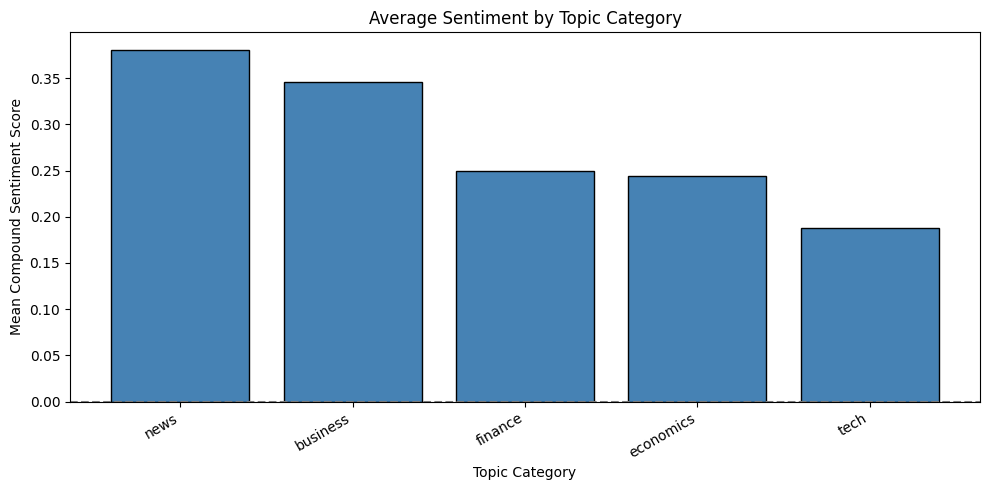

In [ ]:
# bar plot of mean sentiment by topic
plt.figure(figsize=(10, 5))
plt.bar(topic_sentiment.index, topic_sentiment['mean'], color='steelblue', edgecolor='black')
plt.xlabel('Topic Category')
plt.ylabel('Mean Compound Sentiment Score')
plt.title('Average Sentiment by Topic Category')
plt.xticks(rotation=30, ha='right')
plt.axhline(0, color='gray', linestyle='--')
plt.tight_layout()
plt.show()

### VADER Results

The overall sentiment of Bitcoin news in this corpus skews pretty positive, with a mean compound score around 0.36 and the distribution leaning to the right. This was actually surprising to me because I expected crypto news to be more mixed or even negative given how much it focuses on crashes and dramatic events in general. Breaking it down by topic, "news" articles had the highest average sentiment while "tech" and "finance" articles were more neutral. That makes sense since general news tends to highlight adoption and growth stories while tech and finance coverage is more to the point about price movements. One limitation I noticed is that VADER is a general purpose dictionary, so words like "crash" or "dump" that are very normal in crypto news get scored as very negative, which is probably throwing off some of the results.

## Method 2: Unsupervised Topic Modeling (LDA)

For my second method I chose unsupervised topic modeling using LDA. In this context LDA finds groups of words that tend to appear together across documents and assigns each document a mix of these "topics". I chose this method because one of my main research interests from Check In #1 was to explore themes in Bitcoin news coverage and LDA lets those themes emerge from the data instead of me essentially guessing them and hoping they are accurate. For the implementation I filtered out words appearing in fewer than 10 documents to cut down the vocabulary size, and I used 5 topics because it gave a good balance between variety and interpretability.

In [ ]:
# build a gensim dictionary from the preprocessed tokens
dictionary = Dictionary(summaries_toks)

# filter out words that appear in < 10 docs
dictionary.filter_extremes(no_below=10)
dictionary.compactify()

print("Vocabulary size after filtering:", len(dictionary))

Vocabulary size after filtering: 1726


In [ ]:
# build representation
bow = [dictionary.doc2bow(t) for t in summaries_toks]

In [ ]:
# train LDA model with 5 topics
num_topics = 5
lda_model = LdaModel(bow,
                     num_topics=num_topics,
                     id2word=dictionary,
                     random_state=2026,
                     passes=10)

In [ ]:
# print top words for each topic
for i, topic in lda_model.print_topics(num_topics=num_topics, num_words=10):
    print(f"Topic {i}: {topic}")
    print()

Topic 0: 0.072*"traded" + 0.044*"exchanges" + 0.039*"dollar" + 0.032*"day" + 0.023*"worth" + 0.023*"btc" + 0.020*"market" + 0.019*"period" + 0.018*"october" + 0.018*"coin"

Topic 1: 0.037*"hut" + 0.031*"mining" + 0.029*"marketplace" + 0.024*"2022" + 0.023*"btc" + 0.020*"prnewswire" + 0.019*"277" + 0.018*"corp" + 0.015*"production" + 0.015*"oct"

Topic 2: 0.015*"blockchain" + 0.012*"mining" + 0.011*"network" + 0.011*"nydig" + 0.010*"company" + 0.010*"investment" + 0.010*"time" + 0.009*"digital" + 0.009*"firm" + 0.009*"new"

Topic 3: 0.025*"market" + 0.021*"crypto" + 0.020*"price" + 0.016*"cryptocurrency" + 0.015*"trading" + 0.015*"btc" + 0.014*"000" + 0.010*"ethereum" + 0.009*"markets" + 0.009*"time"

Topic 4: 0.024*"crypto" + 0.012*"new" + 0.011*"btc" + 0.008*"digital" + 0.008*"2022" + 0.008*"data" + 0.008*"â" + 0.008*"september" + 0.008*"news" + 0.007*"cryptocurrency"



In [ ]:
# look at the dominant topic example (carried over from CI #3)
for doc_idx in [0, 1, 2]:
    topic_probs = lda_model.get_document_topics(bow[doc_idx])
    dominant = max(topic_probs, key=lambda x: x[1])
    print(f"Article {doc_idx}: {df['title'].iloc[doc_idx][:80]}")
    print(f"  Dominant topic: {dominant[0]} (probability: {dominant[1]:.3f})")
    print()

Article 0: 62% of Bitcoin Has Not Moved in a Year as Long-Term Holders Refuse to Sell
  Dominant topic: 3 (probability: 0.849)

Article 1: The Orange Party Issue Playlist
  Dominant topic: 4 (probability: 0.509)

Article 2: How Many Bitcoins Are There?
  Dominant topic: 4 (probability: 0.577)



### A Cleaner Visualization of the LDA Topics

The text printout is hard to read at a glance in my opinion, so here is the same information in two other visual forms that I wanted to try. The first are just some side by sidebar charts of the top 10 words per topic, and the second is an interactive pyLDAvis map. It shows the topics as circles 2D, where closer means more similar topics, and lets you hover over a topic to see how each word's frequency in that topic compares to its frequency in the corpus overall.

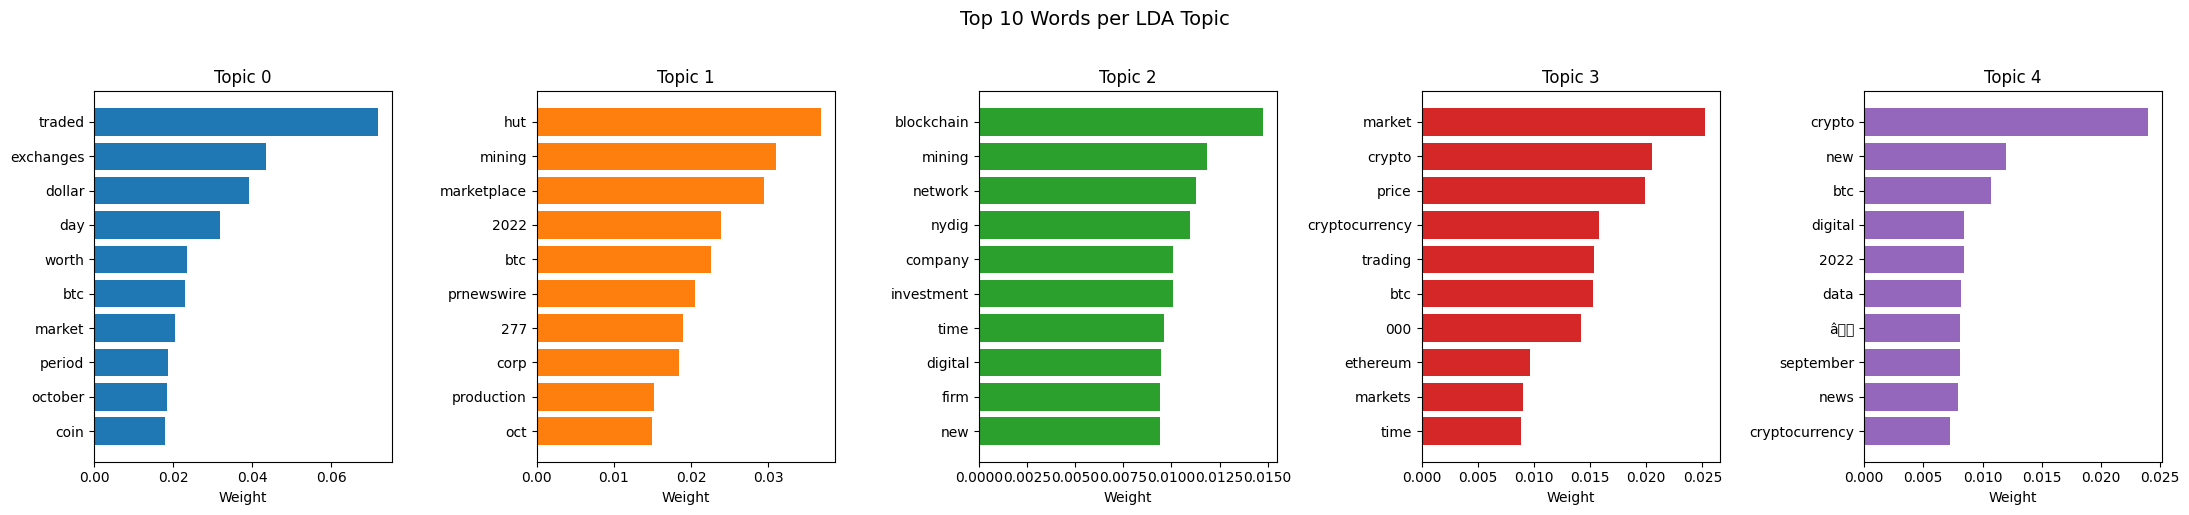

In [ ]:
# top words per topic as side-by-side bar charts
fig, axes = plt.subplots(1, num_topics, figsize=(22, 5))
for i, ax in enumerate(axes):
    topic_words = lda_model.show_topic(i, topn=10)
    words, weights = zip(*topic_words)
    ax.barh(list(words)[::-1], list(weights)[::-1], color=f'C{i}')
    ax.set_title(f'Topic {i}')
    ax.set_xlabel('Weight')
plt.suptitle('Top 10 Words per LDA Topic', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
# interactive topic visualization
pyLDAvis.enable_notebook()
vis = gensimvis.prepare(lda_model, bow, dictionary, sort_topics=False)
vis

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.281421 -0.208223       1        1  14.530509
1      0.158961  0.297886       2        1  12.467482
2     -0.152762  0.035817       3        1  17.316068
3     -0.127112 -0.102494       4        1  31.557273
4     -0.160508 -0.022986       5        1  24.128668, topic_info=                 Term        Freq        Total Category  logprob  loglift
17             traded  966.000000   966.000000  Default  30.0000  30.0000
3           exchanges  619.000000   619.000000  Default  29.0000  29.0000
56             dollar  617.000000   617.000000  Default  28.0000  28.0000
623               hut  424.000000   424.000000  Default  27.0000  27.0000
142               day  604.000000   604.000000  Default  26.0000  26.0000
..                ...         ...          ...      ...      ...      ...
7              market  133.675101  1153.061620   Topic5  -5.1180  -0.7330
64               like   89.572992   178.150004   Topic5  -5.5183   0.7342
102             world   91.939583   413.017934   Topic5  -5.4922  -0.0806
164  cryptocurrencies   91.172649   524.863366   Topic5  -5.5006  -0.3286
92              price   90.917961   671.408978   Topic5  -5.5034  -0.5777

[351 rows x 6 columns], token_table=      Topic      Freq Term
term                      
21        3  0.111494  000
21        4  0.807840  000
21        5  0.080197  000
226       3  0.710111  100
226       4  0.138558  100
...     ...       ...  ...
786       5  0.694148  â
1394      2  0.004322  â¦
1394      3  0.138317  â¦
1394      4  0.561912  â¦
1394      5  0.293923  â¦

[590 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4, 5])

In [ ]:
# assign each article its dominant topic for use in the combined analysis later
def get_dominant_topic(bow_doc):
    probs = lda_model.get_document_topics(bow_doc)
    if not probs:
        return -1
    return max(probs, key=lambda x: x[1])[0]

df['lda_topic'] = [get_dominant_topic(b) for b in bow]
print("Dominant topic distribution:")
print(df['lda_topic'].value_counts().sort_index())

Dominant topic distribution:
lda_topic
0    310
1    211
2    378
3    929
4    672
Name: count, dtype: int64


### LDA Results

The LDA model produced 5 topics that roughly map to different themes in Bitcoin news coverage. Looking at the top words, the topics break down into trading and market activity ("traded", "exchanges", "market", "dollar"), mining and mining companies ("mining", "production", "corp"), blockchain and investment infrastructure ("blockchain", "network", "investment", "digital"), price movements and cryptocurrencies more broadly ("price", "trading", "cryptocurrency", "ethereum"), and general crypto news ("crypto", "new", "data", "news"). These themes mostly line up with what I expected based on Check In #1, which is a good sign that the model is picking up on real patterns that I am interested in. The topics are not perfectly clean though because dominant terms like "btc" and "crypto" show up across multiple topics, making them overlap a bit.

## Comparing the Two Methods

Comparing the two methods, I think LDA gave the more interesting results for this dataset. VADER gave a advanced picture of sentiment but the results felt limited because the scores come from a general dictionary that does not really capture crypto specific language, and the differences across topic categories were minimal.

LDA on the other hand actually surfaced real themes that map onto different kinds of Bitcoin coverage, which is more directly useful for my research question about what narratives dominate Bitcoin news. That said, VADER was simpler and faster to run, and I think the two methods could work well together by scoring sentiment within each LDA topic to see which themes are covered more positively or negatively.

## Method 3: Transformer-Based Sentiment with FinBERT

The biggest limitation I kept hitting with VADER in Check In #3 is that it is a more general-purpose lexicon. It does not know that "crash" and "dump" are routine vocabulary in financial and crypto news. An idea i had to counter this is to use a model that has actually been trained on financial text. FinBERT is a BERT model which is fine-tuned on financial news for sentiment classification.

There are a few differences I wanted to talk about. VADER scores each word in isolation and combines them with rules, while FinBERT looks at the whole sentence in context, so it should be able to figure out that "BTC crashed but recovered quickly" is not as negative as "Bitcoin crashed and lost half its value". FinBERT has seen words like "crash" and "bear" used in financial contexts and learned what they actually signal there. The other difference is that FinBERT outputs discrete labels rather than a continuous score. It picks one of three labels ("positive", "negative", or "neutral") along with a confidence score from 0 to 1, so to compare it against VADER I convert the label into a signed score (positive becomes +score, negative becomes -score, neutral is 0).

For FinBERT and CryptoBERT I use the raw article summaries rather than the preprocessed token strings, because I saw that BERT models actually use punctuation, capitalization, and stopwords as context.

In [ ]:
# detect device
device = 0 if torch.cuda.is_available() else -1
print("Using:", "GPU (cuda)" if device == 0 else "CPU")

# load FinBERT pipeline
finbert = pipeline("sentiment-analysis",
                   model="ProsusAI/finbert",
                   device=device,
                   truncation=True,
                   max_length=512)

Using: GPU (cuda)


config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

BertForSequenceClassification LOAD REPORT from: ProsusAI/finbert
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [ ]:
# run FinBERT on the raw summaries
summaries_raw = df['summary'].tolist()
finbert_results = finbert(summaries_raw, batch_size=16)

df['finbert_label'] = [r['label'].lower() for r in finbert_results]
df['finbert_score'] = [r['score'] for r in finbert_results]

# build a signed continuous score so I can compare against VADER's compound score
def signed_score(row):
    s = row['finbert_score']
    if row['finbert_label'] == 'positive':
        return s
    if row['finbert_label'] == 'negative':
        return -s
    return 0.0
df['finbert_signed'] = df.apply(signed_score, axis=1)

df[['title', 'finbert_label', 'finbert_score', 'finbert_signed']].head()

,title,finbert_label,finbert_score,finbert_signed
0,62% of Bitcoin Has Not Moved in a Year as Long...,neutral,0.724846,0.000000
1,The Orange Party Issue Playlist,neutral,0.707043,0.000000
2,How Many Bitcoins Are There?,neutral,0.941133,0.000000
3,Bitcoin 2008â2022: From Bouncing Baby To Tro...,neutral,0.794626,0.000000
4,"Bitcoin Lightning Network capacity strikes 5,0...",positive,0.814561,0.814561


In [ ]:
# label distribution
finbert_dist = df['finbert_label'].value_counts(normalize=True) * 100
print("FinBERT label distribution (%):")
print(finbert_dist.round(1))

FinBERT label distribution (%):
finbert_label
neutral     46.2
negative    29.7
positive    24.1
Name: proportion, dtype: float64


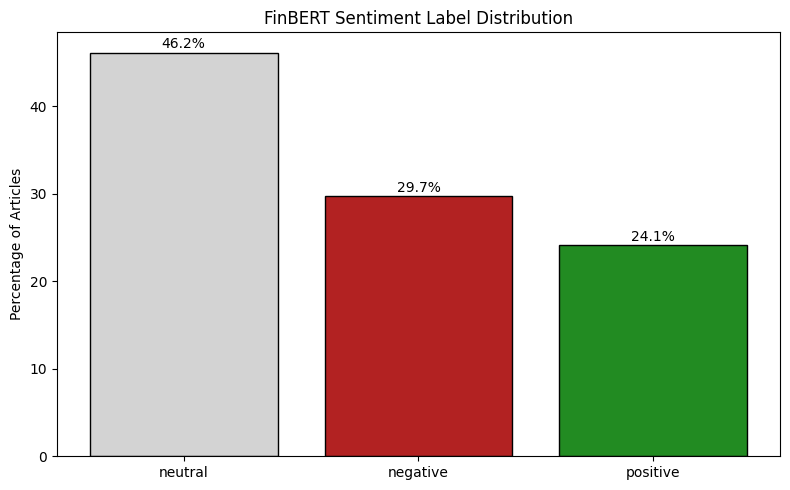

In [ ]:
# bar chart of label distribution
color_map = {'positive': 'forestgreen', 'neutral': 'lightgray', 'negative': 'firebrick'}
plt.figure(figsize=(8, 5))
bars = plt.bar(finbert_dist.index, finbert_dist.values,
               color=[color_map.get(l, 'steelblue') for l in finbert_dist.index],
               edgecolor='black')
plt.ylabel('Percentage of Articles')
plt.title('FinBERT Sentiment Label Distribution')
for b, v in zip(bars, finbert_dist.values):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.5, f'{v:.1f}%', ha='center')
plt.tight_layout()
plt.show()

### FinBERT Results

FinBERT classifies 46.2% of the articles as neutral, 29.7% as negative, and 24.1% as positive. This is already pretty different from the VADER picture in Check In #3, where the corpus skewed clearly positive on average. FinBERT thinks most of the coverage is either neutral or slightly negative instead. The shift probably comes from exactly the issue where VADER picks up on words like "growth", "strong", and "gain" as positive, while FinBERT sees those as normal descriptive vocab and calls them neutral. The fact that FinBERT is also flagging about 30% of the articles as outright negative is interesting and not something I expected.

## Method 4: Transformer-Based Sentiment with CryptoBERT

FinBERT was trained on financial news, but financial news and crypto news are not really the same thing even though they have similarities. The crypto domain has its own vocab and its own conventions, which a model trained on traditional financial reporting may still struggle with. CryptoBERT is a BERT model fine-tuned specifically on crypto-domain text, which should make it the most domain accurate option of the three sentiment methods I am running.

SOme things I wanted to point about about the model after reading up on it. CryptoBERT was trained primarily on social media crypto text (Reddit, Twitter, Telegram), not on news articles, so while it knows crypto vocab very well, what it was trained on is pretty different than the data in this corpus. Instead of using "positive", "neutral", and "negative" CryptoBERT outputs labels like "bullish", "neutral", and "bearish", which are sypto specific terms that basically have the same meaining as the standard 3 outputs. I rename them below to keep the comparison clean.

In [ ]:
# load CryptoBERT pipeline
cryptobert = pipeline("sentiment-analysis",
                      model="ElKulako/cryptobert",
                      tokenizer="ElKulako/cryptobert",
                      device=device,
                      truncation=True,
                      max_length=512)

config.json:   0%|          | 0.00/932 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: ElKulako/cryptobert
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/957 [00:00<?, ?B/s]

In [ ]:
# run on raw summaries
cryptobert_results = cryptobert(summaries_raw, batch_size=16)

df['cryptobert_raw_label'] = [r['label'].lower() for r in cryptobert_results]
df['cryptobert_score'] = [r['score'] for r in cryptobert_results]

# normalize labels to match the FinBERT scheme
LABEL_MAP = {'bullish': 'positive', 'neutral': 'neutral', 'bearish': 'negative'}
df['cryptobert_label'] = df['cryptobert_raw_label'].map(lambda l: LABEL_MAP.get(l, l))

# signed continuous score
def signed_score_cb(row):
    s = row['cryptobert_score']
    if row['cryptobert_label'] == 'positive':
        return s
    if row['cryptobert_label'] == 'negative':
        return -s
    return 0.0
df['cryptobert_signed'] = df.apply(signed_score_cb, axis=1)

df[['title', 'cryptobert_raw_label', 'cryptobert_label', 'cryptobert_score', 'cryptobert_signed']].head()

,title,cryptobert_raw_label,cryptobert_label,cryptobert_score,cryptobert_signed
0,62% of Bitcoin Has Not Moved in a Year as Long...,bullish,positive,0.508595,0.508595
1,The Orange Party Issue Playlist,neutral,neutral,0.655626,0.000000
2,How Many Bitcoins Are There?,bullish,positive,0.672487,0.672487
3,Bitcoin 2008â2022: From Bouncing Baby To Tro...,bullish,positive,0.579759,0.579759
4,"Bitcoin Lightning Network capacity strikes 5,0...",bullish,positive,0.612282,0.612282


In [ ]:
# label distribution
cryptobert_dist = df['cryptobert_label'].value_counts(normalize=True) * 100
print("CryptoBERT label distribution (%):")
print(cryptobert_dist.round(1))

CryptoBERT label distribution (%):
cryptobert_label
neutral     53.9
positive    42.5
negative     3.6
Name: proportion, dtype: float64


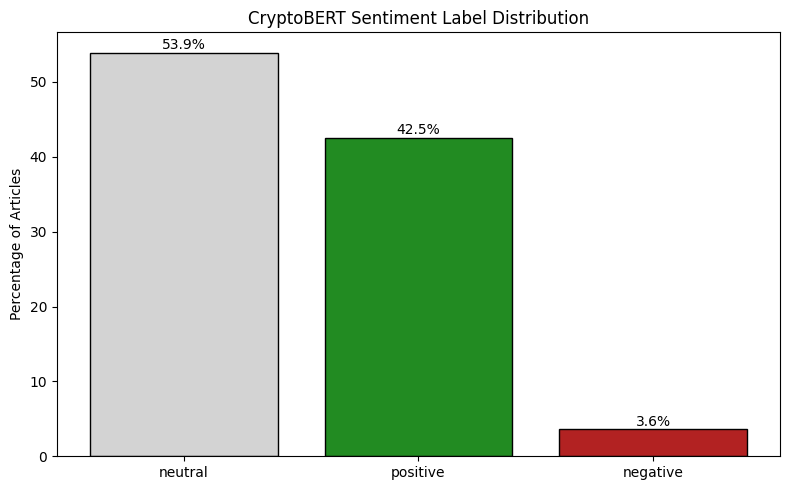

In [ ]:
# bar chart of CryptoBERT distribution
plt.figure(figsize=(8, 5))
bars = plt.bar(cryptobert_dist.index, cryptobert_dist.values,
               color=[color_map.get(l, 'steelblue') for l in cryptobert_dist.index],
               edgecolor='black')
plt.ylabel('Percentage of Articles')
plt.title('CryptoBERT Sentiment Label Distribution')
for b, v in zip(bars, cryptobert_dist.values):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.5, f'{v:.1f}%', ha='center')
plt.tight_layout()
plt.show()

### CryptoBERT Results

CryptoBERT classifies 53.9% of the articles as neutral, 42.5% as positive (bullish), and only 3.6% as negative (bearish). The thing that stands out to me the most is how rarely CryptoBERT predicts bearish. Basically it thinks almost nothing in this corpus is negative coverage. I feel like that could be consistent with crypto social media leaning generally bullish, but it also kind of feels like the model is not detecting negative coverage that is actually there.

## Comparing the Three Sentiment Methods

Now that I have all three sentiment methods on the same articles, I can compare them directly. The main things I look at are whether the three methods agree about the overall tone of the corpus, whether they tend to disagree on the same articles or different ones, and when they disagree, what those articles actually look like.

To put VADER on the same scale as the two BERT models, I convert its compound score into a discrete label using the standard VADER thresholds.

In [ ]:
# convert VADER compound score into a label so it is on the same scale as the BERT models
def vader_to_label(c):
    if c >= 0.05:
        return 'positive'
    if c <= -0.05:
        return 'negative'
    return 'neutral'

df['vader_label'] = df['compound'].apply(vader_to_label)

# build a comparison frame
comp = pd.DataFrame({
    'VADER': df['vader_label'].value_counts(normalize=True) * 100,
    'FinBERT': df['finbert_label'].value_counts(normalize=True) * 100,
    'CryptoBERT': df['cryptobert_label'].value_counts(normalize=True) * 100,
}).reindex(['positive', 'neutral', 'negative']).fillna(0).round(1)

print("Sentiment label distribution (%): VADER vs FinBERT vs CryptoBERT")
print(comp)

Sentiment label distribution (%) — VADER vs FinBERT vs CryptoBERT
          VADER  FinBERT  CryptoBERT
positive   72.6     24.1        42.5
neutral     6.8     46.2        53.9
negative   20.5     29.7         3.6


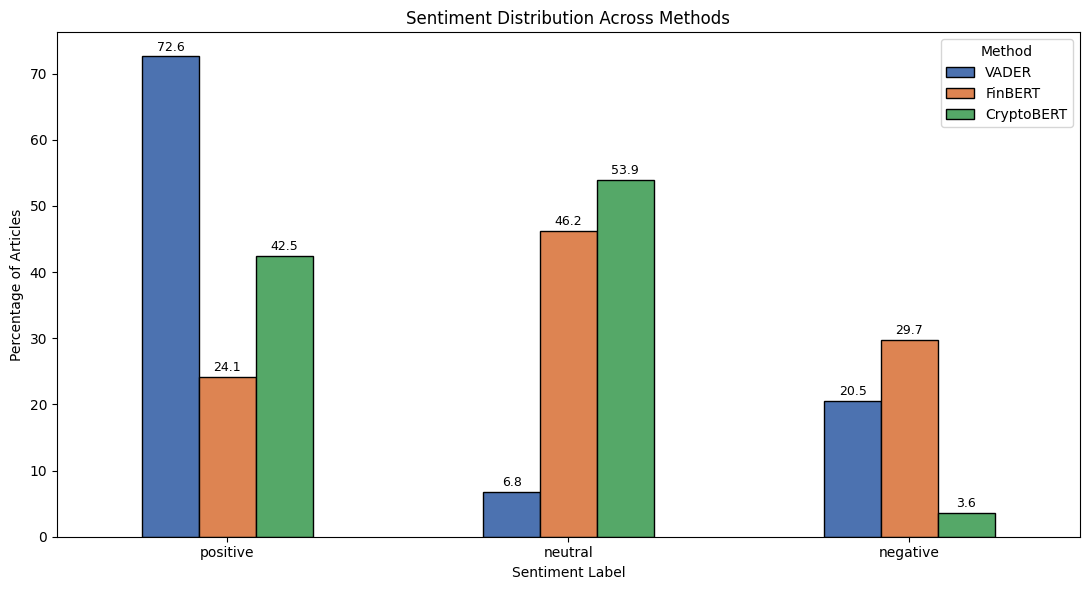

In [ ]:
# grouped bar chart
ax = comp.plot(kind='bar', figsize=(11, 6),
               color=['#4C72B0', '#DD8452', '#55A868'],
               edgecolor='black')
plt.title('Sentiment Distribution Across Methods')
plt.ylabel('Percentage of Articles')
plt.xlabel('Sentiment Label')
plt.xticks(rotation=0)
plt.legend(title='Method')
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=2, fontsize=9)
plt.tight_layout()
plt.show()

### Pairwise Agreement

In [ ]:
def pct_agree(a, b):
    return (df[a] == df[b]).mean() * 100

print(f"VADER ↔ FinBERT agreement:      {pct_agree('vader_label', 'finbert_label'):.1f}%")
print(f"VADER ↔ CryptoBERT agreement:   {pct_agree('vader_label', 'cryptobert_label'):.1f}%")
print(f"FinBERT ↔ CryptoBERT agreement: {pct_agree('finbert_label', 'cryptobert_label'):.1f}%")

VADER ↔ FinBERT agreement:      38.4%
VADER ↔ CryptoBERT agreement:   38.3%
FinBERT ↔ CryptoBERT agreement: 29.5%


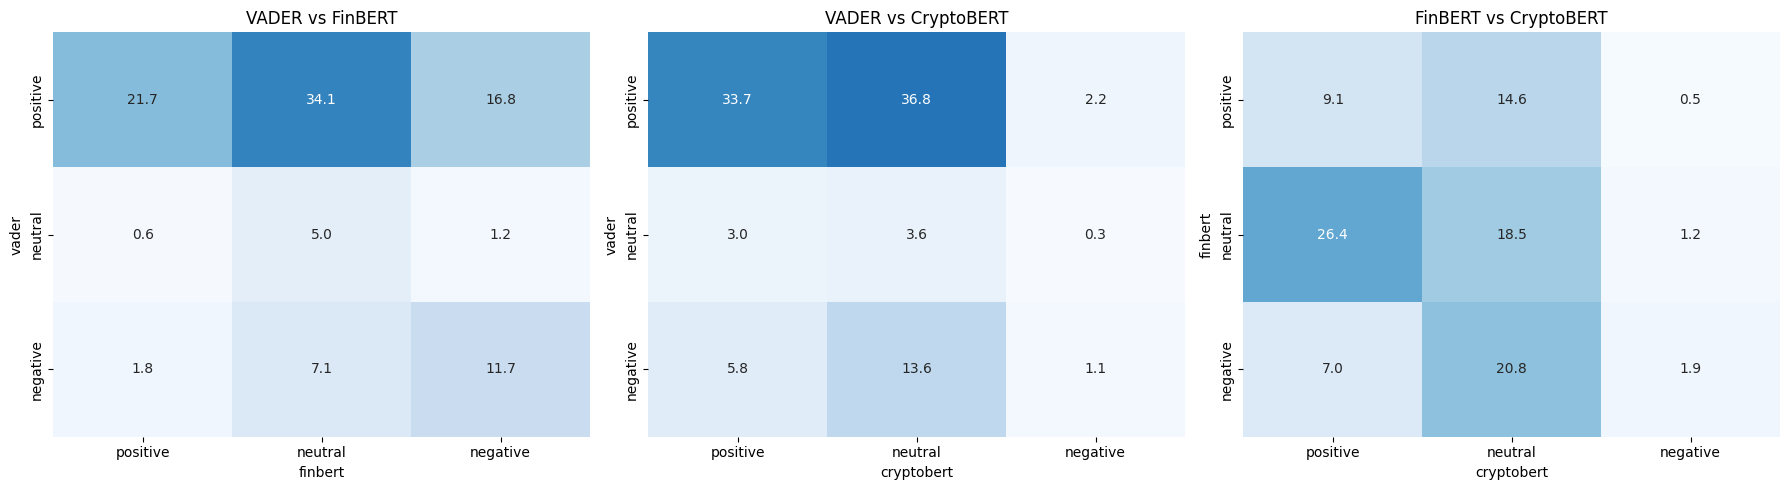

In [ ]:
# pairwise confusion-style heatmaps
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
pairs = [('vader_label', 'finbert_label', 'VADER vs FinBERT'),
         ('vader_label', 'cryptobert_label', 'VADER vs CryptoBERT'),
         ('finbert_label', 'cryptobert_label', 'FinBERT vs CryptoBERT')]
for ax, (a, b, title) in zip(axes, pairs):
    ct = pd.crosstab(df[a], df[b], normalize='all') * 100
    ct = ct.reindex(index=['positive','neutral','negative'],
                    columns=['positive','neutral','negative']).fillna(0)
    sns.heatmap(ct, annot=True, fmt='.1f', cmap='Blues', cbar=False, ax=ax, vmin=0, vmax=50)
    ax.set_title(title)
    ax.set_xlabel(b.replace('_label', ''))
    ax.set_ylabel(a.replace('_label', ''))
plt.tight_layout()
plt.show()

### Examples Where the Methods Disagree

To make the comparison more concrete, here are a handful of articles where the three methods disagree. Looking at the actual text helps me decide which method is doing a better job in any given case.

In [ ]:
# pull articles where the three methods disagree
mask = ~((df['vader_label'] == df['finbert_label']) & (df['finbert_label'] == df['cryptobert_label']))
disagreement = df[mask][['title', 'summary', 'vader_label', 'finbert_label', 'cryptobert_label']]

sample = disagreement.sample(n=min(6, len(disagreement)), random_state=42)
for _, row in sample.iterrows():
    print("Title    :", str(row['title'])[:90])
    print(f"  VADER  : {row['vader_label']:<10} FinBERT: {row['finbert_label']:<10} CryptoBERT: {row['cryptobert_label']}")
    print("  Summary:", str(row['summary'])[:280].replace('\n', ' '), "...")
    print()

Title    : Oktoberfest for cryptos: Bitcoin tops $20,000; what's in store this month
  VADER  : negative   FinBERT: positive   CryptoBERT: neutral
  Summary: Bitcoin, the largest crypto asset, has topped the $20,000 mark once again on Tuesday. The oldest existing cryptocurrency has been flirting with the key psychological level lately. According to the data from Coinmarketcap, Bitcoin surged about 5 per cent in the last 24 hours to 20 ...

Title    : Crypto Boom Review: Unleashing The Fundamentals
  VADER  : positive   FinBERT: neutral    CryptoBERT: neutral
  Summary: In a short amount of time, the crypto exchange bot identified as Crypto Boom has become extremely popular. The software's creators have high hopes for its potential applications, outcomes, and implementation. We chose to write this evaluation of Crypto Boom to learn more about th ...

Title    : Bitcoin's next bull run may have a USDC connection, here's âhow'
  VADER  : positive   FinBERT: neutral    CryptoBERT: positi

### Interpretation of the Three-Way Comparison

The main thing I noticed is that the three methods really do not agree with each other, and the way they disagree actually says a lot about each one's biases.

VADER is by far the most positive of the three, with 72.6% positive and only 6.8% neutral. It picks up on common upbeat words and treats them all as positive, and it almost never flags anything as neutral because there is usually at least one charged word in any 100-word summary.

FinBERT classifies the most articles as neutral (46.2%) but is also the most negative of the three (29.7% negative). FinBERT calls a lot of routine market reporting neutral, but it is also more willing than the other two to call dramatic price movement outright negative.

CryptoBERT is the strangest of the three to me. It predicts bearish only 3.6% of the time, basically never, and splits the rest between neutral (53.9%) and positive (42.5%). The thing that surprised me the most is that CryptoBERT and FinBERT have the lowest agreement of any pair (29.5%) even though they are both BERT-based. I had expected the two BERT models to look much more similar to each other than to VADER, and they do not.

The pairwise agreement numbers (38.4% for VADER and FinBERT, 38.3% for VADER and CryptoBERT, 29.5% for FinBERT and CryptoBERT) are all really low, which kind of tells me that the answer to my research quesition at this point gets a different answer depending on which model you ask.

I do think FinBERT is still objectivley the best choice for sentiment in this corpus. Compared to the other 2 FinBERT sits closest to what looks reasonable when I read the disagreement examples by hand.

## Combined Analysis: Sentiment per LDA Topic

This is the next thing I wanteed to do, combining the LDA topic assignments with the sentiment scores to see whether different themes in the corpus have different sentiment patterns. For example, are mining-and-companies articles more positive than price-movement articles?

For each LDA topic I compute the mean sentiment under each method (VADER compound score, FinBERT signed score, CryptoBERT signed score). All three are on the -1 to +1 scale where 0 is neutral, so they can be compared directly.

In [ ]:
# average sentiment per topic, by method
topic_sent = df.groupby('lda_topic').agg(
    n_articles=('article_id', 'count'),
    vader=('compound', 'mean'),
    finbert=('finbert_signed', 'mean'),
    cryptobert=('cryptobert_signed', 'mean'),
).round(3)
print("Mean sentiment per LDA topic, by method:")
print(topic_sent)

Mean sentiment per LDA topic, by method:
           n_articles  vader  finbert  cryptobert
lda_topic                                        
0                 310  0.346   -0.262       0.123
1                 211  0.516    0.343       0.262
2                 378  0.480    0.177       0.323
3                 929  0.306   -0.161       0.229
4                 672  0.317   -0.062       0.247


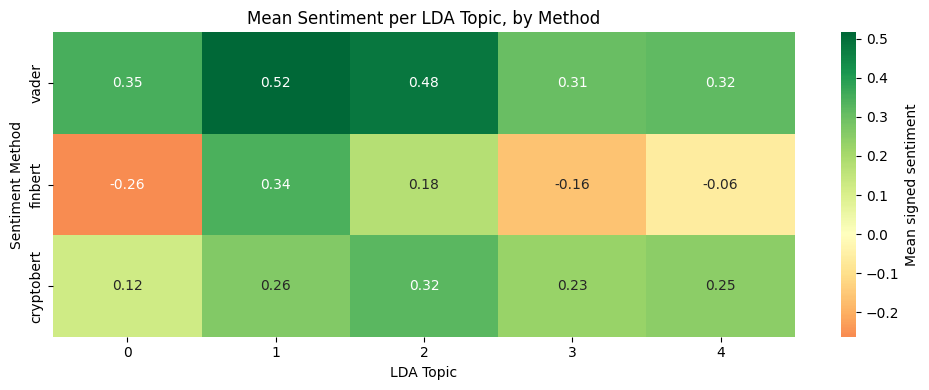

In [ ]:
# heatmap
heatmap_data = topic_sent[['vader', 'finbert', 'cryptobert']].T

plt.figure(figsize=(10, 4))
sns.heatmap(heatmap_data, annot=True, fmt='.2f', cmap='RdYlGn', center=0,
            cbar_kws={'label': 'Mean signed sentiment'})
plt.title('Mean Sentiment per LDA Topic, by Method')
plt.xlabel('LDA Topic')
plt.ylabel('Sentiment Method')
plt.tight_layout()
plt.show()

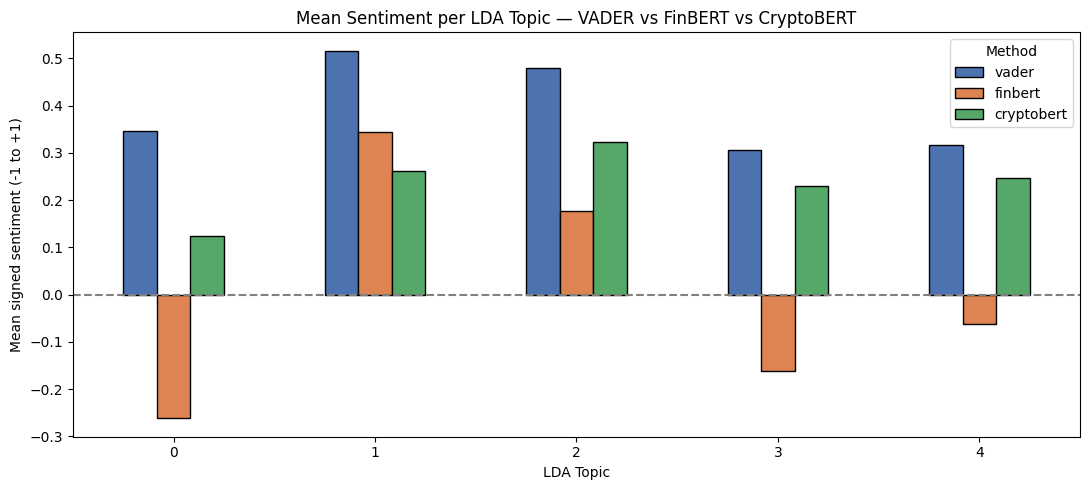

In [ ]:
# grouped bar version of the same data
topic_sent[['vader', 'finbert', 'cryptobert']].plot(
    kind='bar', figsize=(11, 5),
    color=['#4C72B0', '#DD8452', '#55A868'],
    edgecolor='black')
plt.axhline(0, color='gray', linestyle='--')
plt.title('Mean Sentiment per LDA Topic: VADER vs FinBERT vs CryptoBERT')
plt.ylabel('Mean signed sentiment (-1 to +1)')
plt.xlabel('LDA Topic')
plt.xticks(rotation=0)
plt.legend(title='Method')
plt.tight_layout()
plt.show()

### Sentiment-per-Topic Results

Looking at the table and the heatmap, a few patterns stand out to me. The mining and mining-companies topic (Topic 1) is the most positive of the five under both VADER and FinBERT, and is one of the top under CryptoBERT. These articles are about production targets and new equipment, which sound positive across the board. The trading and exchange topic (Topic 0) is the most negative under both FinBERT and CryptoBERT, and the price-movement topic (Topic 3) is the most negative under VADER. Both of those topics are heavy on words like "decline", "loss" and "crash", so this is expecetd.

The interesting part is that FinBERT actually goes net negative on three of the five topics (trading, price movements, and general news), while VADER and CryptoBERT stay positive on every topic. That gap is the same one I saw in the overall sentiment comparison earlier. FinBERT is willing to call coverage negative in situations where the other two methods do not, and that shows up consistently when broken down by topic.

## Final Results

Pulling all of the pieces from this notebook and the past check-ins together, here are the main findings of this project.

The choice of sentiment method really does matter for this corpus. VADER labels 72.6% of the articles as positive, FinBERT labels only 24.1% as positive, and CryptoBERT splits things differently again with 42.5% positive and only 3.6% negative. The pairwise agreement rates are all under 40%, which is really low for three methods that are supposed to be measuring the same thing.

Domain-specificity helps but more is not always better. FinBERT gives results that make more general sense than VADER because it does not over-react to words like "crash" and "growth" that are routine in finance. CryptoBERT is the most domain-specific of the three but its training data is social media not news, and that is probably why it almost never predicts bearish. For the sentiment in this corpus FinBERT is the most logocal single choice.

LDA brought out five interpretable themes that roughly map onto trading and market activity, mining and mining companies, blockchain and infrastructure, price movements, and general crypto news.

Sentiment varies by theme and the methods mostly agree on the ranking. Mining articles score consistently positive across all three methods, while trading and price-movement articles score lowest. The methods disagree on the absolute level of sentiment but agree on which themes are more positive and which are more negative.

## Challenges

One of the biggest challenges I ran into is that general sentiment dictionaries like VADER do not handle crypto specific language well. Words like "crash", "dump", and "bear" have strong negative connotations in normal English but are used pretty casually in crypto news to describe routine price movements, which means VADER might be scoring some articles as more negative than they actually are.

Another challenge is that dominant terms like "bitcoin", "btc", and "crypto" show up so often that they appear across multiple LDA topics and make the topic boundaries fuzzy. Also the "topic" column in the dataset is not balanced at all, with most articles labeled as "news" and only a small number in categories like "tech" or "economics", which definitley negativley impacts comparisons across categories.


None of the three sentiment methods I am using has a ground-truth label set behind it for this corpus. I am basically comparing the three methods against each other and using internal consistency to decide which one I trust more, but I do not have any labeled crypto news data to actually validate any of them against. So calling FinBERT "the best one" is an argument rather than a proof.


I am also working with article summaries rather than full body text, since that is what the dataset provides. Summaries tend to compress the news angle and may amplify or flatten the underlying sentiment relative to the full article.

## Conclusion and Next Steps

Coming back to my research question, how does sentiment in Bitcoin news vary across themes and how much does the choice of method matter, the short answer is that the method matters a lot and the themes matter a fair amount, but the cross-method ranking of themes is pretty stable even when the absolute sentiment levels are very different. That is what I see as the most interesting result of the project.

If I had unlimited time and rescources I would want to try building or fine-tuning a crypto-news-specific sentiment model. This would solve a lot of the issues I had in this project outright.

Getting the full article bodies rather than just the summaries would be another good improvement. The Hugging Face dataset only provides summaries, so pulling the full text from the article URLs where they are still accessible would give me a much richer signal for both sentiment and topic modeling.

## References

**Corpus**
- Lim, Khai Hern. *bitcoin-news-articles-text-corpora*. Hugging Face Datasets. https://huggingface.co/datasets/khaihernlow/bitcoin-news-articles-text-corpora

**Methods and tools**
- Araci, D. (2019). FinBERT: Financial Sentiment Analysis with Pre-trained Language Models. arXiv:1908.10063. Model: https://huggingface.co/ProsusAI/finbert
- ElKulako. *CryptoBERT: A Pre-trained NLP Model for Cryptocurrency Sentiment Analysis*. Hugging Face. https://huggingface.co/ElKulako/cryptobert

**Libraries**
- gensim (preprocessing + LDA): https://radimrehurek.com/gensim/
- nltk + VADER: https://www.nltk.org/
- transformers (Hugging Face): https://huggingface.co/docs/transformers
- pyLDAvis: https://github.com/bmabey/pyLDAvis
- pandas, numpy, matplotlib, seaborn, wordcloud

**Course materials referenced**
- DACSS 758 weekly labs (Weeks 4–13), specificaly the Week 9 dictionaries / VADER lab, the Week 10–11 LDA / topic modeling labs, and the Week 12–13 ELMo / BERT / LLMs labs.